# Experiment 03: Hole Radius Sensitivity

This notebook sweeps the radius of an interior hole and compares Dice, BCE, Betti numbers, and PCE-based topology differences.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
source_dir = project_root / 'src'
if not source_dir.exists():
    source_dir = Path('/home/yejuny2/Desktop/code/PCE/topological_segmentation/src')
if str(source_dir) not in sys.path:
    sys.path.append(str(source_dir))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from topological_segmentation.data.perturbations import add_hole
from topological_segmentation.data.synthetic_2d import make_disk
from topological_segmentation.losses.segmentation import binary_cross_entropy, dice_score
from topological_segmentation.topology.betti import compute_betti_numbers
from topological_segmentation.topology.persistence import get_persistence_diagram
from topological_segmentation.topology.pce import finite_birth_persistence, pce_from_diagrams

## 1. Generate predictions by hole radius

The ground truth is a filled disk. For each radius, a centered circular hole is removed from the prediction. Radius 0 is the unperturbed prediction.

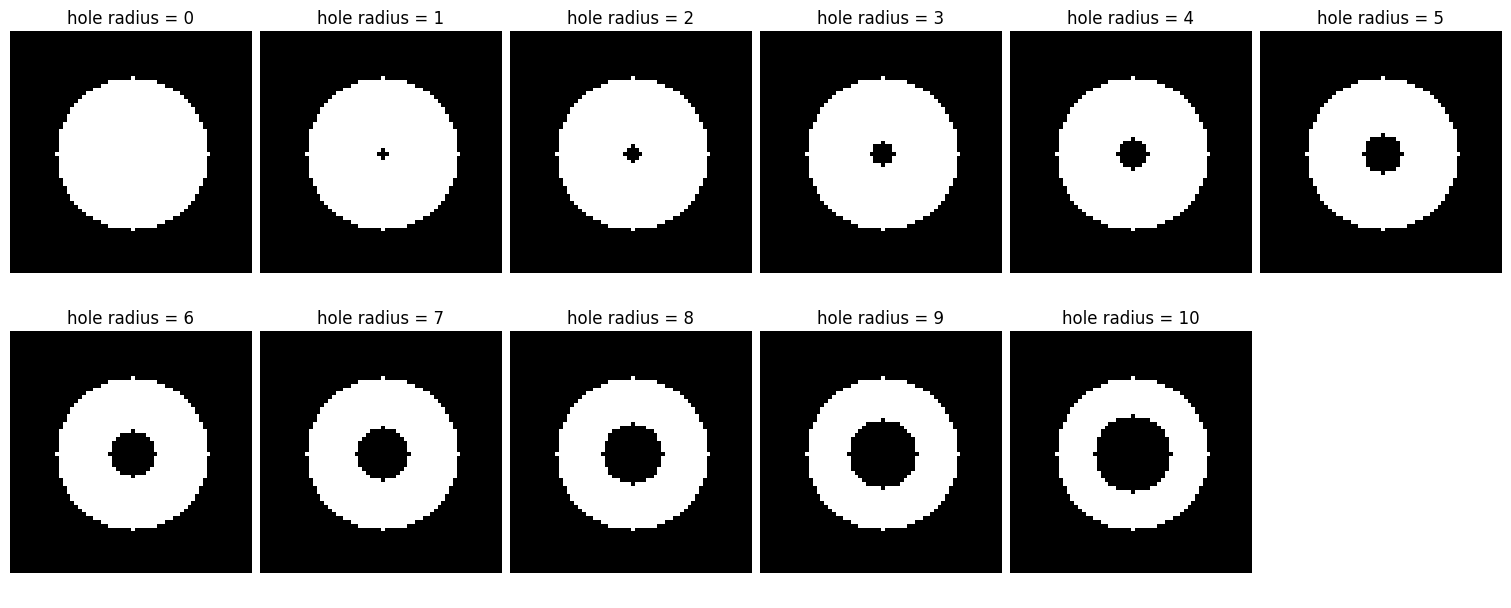

In [2]:
gt = make_disk(size=64, radius=20)
hole_radii = range(0, 11)
preds = {
    radius: gt.copy() if radius == 0 else add_hole(gt, radius=radius)
    for radius in hole_radii
}

fig, axes = plt.subplots(2, 6, figsize=(15, 6), constrained_layout=True)
for ax, radius in zip(axes.ravel(), hole_radii):
    ax.imshow(preds[radius], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'hole radius = {radius}')
    ax.axis('off')
axes.ravel()[-1].axis('off')
plt.show()

## 2. Compute segmentation and topology metrics

PCE is computed in the prediction-to-ground-truth direction for H1. This direction is necessary because the filled-disk ground truth has no finite H1 feature, while a prediction with a hole does.

In [3]:
def diagram_for(mask, homology_dimension):
    entries = get_persistence_diagram(mask.astype(float), homology_dimension)
    return finite_birth_persistence(entries)


gt_h1 = diagram_for(gt, homology_dimension=1)
rows = []
for radius, pred in preds.items():
    beta_0, beta_1 = compute_betti_numbers(pred)
    pred_h1 = diagram_for(pred, homology_dimension=1)
    pce_report = pce_from_diagrams(pred_h1, gt_h1, tau=1.0)
    lifetime = float(pred_h1[:, 1].max()) if len(pred_h1) else np.nan
    rows.append({
        'hole_radius': radius,
        'dice': float(dice_score(pred, gt)),
        'bce': float(binary_cross_entropy(pred.astype(float), gt.astype(float))),
        'beta_0': beta_0,
        'beta_1': beta_1,
        'h1_lifetime': lifetime,
        'pce_difference_h1': pce_report.entropy_excess,
        'unexplained_mass_h1': pce_report.unexplained_mass,
        'pce_status_h1': pce_report.status,
    })

results_df = pd.DataFrame(rows)
display(results_df.style.format({
    'dice': '{:.4f}',
    'bce': '{:.4f}',
    'h1_lifetime': '{:.4f}',
    'pce_difference_h1': '{:.4f}',
    'unexplained_mass_h1': '{:.4f}',
}, na_rep='undefined'))

,hole_radius,dice,bce,beta_0,beta_1,h1_lifetime,pce_difference_h1,unexplained_mass_h1,pce_status_h1
0,0,1.0000,0.0000,1,0,undefined,0.0000,0.0000,both_empty
1,1,0.9980,0.0225,1,1,1.0000,0.1250,0.1175,ok
2,2,0.9948,0.0585,1,1,1.0000,0.1250,0.1175,ok
3,3,0.9883,0.1304,1,1,1.0000,0.1250,0.1175,ok
4,4,0.9801,0.2204,1,1,1.0000,0.1250,0.1175,ok
5,5,0.9667,0.3643,1,1,1.0000,0.1250,0.1175,ok
6,6,0.9529,0.5082,1,1,1.0000,0.1250,0.1175,ok
7,7,0.9370,0.6701,1,1,1.0000,0.1250,0.1175,ok
8,8,0.9150,0.8860,1,1,1.0000,0.1250,0.1175,ok
9,9,0.8881,1.1378,1,1,1.0000,0.1250,0.1175,ok


## 3. Compare metric sensitivity to hole radius

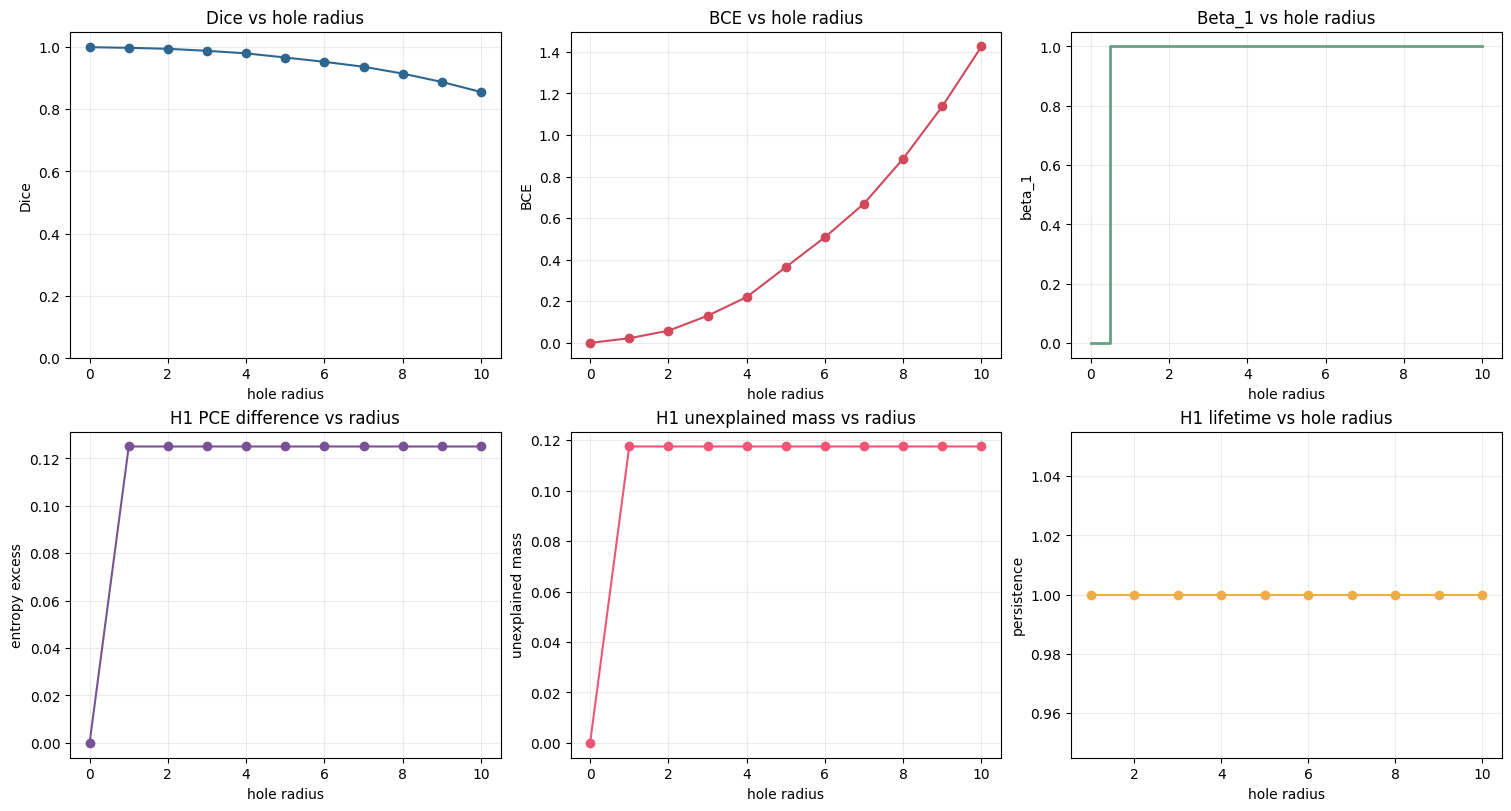

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
radius = results_df['hole_radius']

axes[0, 0].plot(radius, results_df['dice'], marker='o', color='#2f6690')
axes[0, 0].set_title('Dice vs hole radius')
axes[0, 0].set_ylabel('Dice')
axes[0, 0].set_ylim(0, 1.05)

axes[0, 1].plot(radius, results_df['bce'], marker='o', color='#d1495b')
axes[0, 1].set_title('BCE vs hole radius')
axes[0, 1].set_ylabel('BCE')

axes[0, 2].step(radius, results_df['beta_1'], where='mid', color='#66a182', linewidth=2)
axes[0, 2].set_title('Beta_1 vs hole radius')
axes[0, 2].set_ylabel('beta_1')

axes[1, 0].plot(radius, results_df['pce_difference_h1'], marker='o', color='#7a5195')
axes[1, 0].set_title('H1 PCE difference vs radius')
axes[1, 0].set_ylabel('entropy excess')

axes[1, 1].plot(radius, results_df['unexplained_mass_h1'], marker='o', color='#ef5675')
axes[1, 1].set_title('H1 unexplained mass vs radius')
axes[1, 1].set_ylabel('unexplained mass')

axes[1, 2].plot(radius, results_df['h1_lifetime'], marker='o', color='#edae49')
axes[1, 2].set_title('H1 lifetime vs hole radius')
axes[1, 2].set_ylabel('persistence')

for ax in axes.ravel():
    ax.set_xlabel('hole radius')
    ax.grid(alpha=0.25)

plt.show()

## 4. Persistence diagrams for selected radii

The binary filtration may assign the same birth and lifetime values to holes of different geometric sizes. This plot makes that behavior explicit.

In [ ]:
selected_radii = [0, 1, 4, 8, 10]
fig, axes = plt.subplots(1, len(selected_radii), figsize=(16, 3.5), constrained_layout=True)
for ax, selected_radius in zip(axes, selected_radii):
    diagram = diagram_for(preds[selected_radius], homology_dimension=1)
    if len(diagram):
        ax.scatter(diagram[:, 0], diagram[:, 1], s=90, color='#66a182', edgecolor='black')
    else:
        ax.text(0.5, 0.5, 'no finite H1 features', ha='center', va='center', transform=ax.transAxes)
    ax.set_title(f'radius = {selected_radius}')
    ax.set_xlabel('birth')
    ax.set_ylabel('persistence')
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=0.25)
plt.show()

## Interpretation

- Dice decreases as the removed hole becomes larger, while BCE increases.
- `beta_1` changes from 0 to 1 once a hole is present.
- H1 PCE detects the appearance of a hole relative to the filled-disk reference.
- If H1 PCE remains nearly constant across positive radii, that is a limitation of the current binary `0/1` filtration: geometric hole size is not encoded in the persistence lifetime.
- A later soft probability or distance-based filtration experiment is needed to test whether PCE responds continuously to geometric severity.